# UncertainKernel vs. three vanilla-gpytorch alternatives

Same toy problem as `kernelTesting.ipynb` (noisy sine, uncertain inputs), fit five ways, with inputs
that are genuinely jittered (every model only ever sees a noisy observed x; y is generated from a hidden
true x):

1. **Plain GP** — standard `RBFKernel` + `GaussianLikelihood`, input uncertainty ignored entirely (baseline).
2. **UncertainKernel** — this repo's exact closed-form marginalization (Dallaire et al. 2009).
3. **NIGP-style** — stock GPyTorch only. Approximate McHutchon & Rasmussen (2011): fit a plain GP, linearize
   the posterior mean at each training point, push input variance through as extra *output* noise via
   `FixedNoiseGaussianLikelihood`, and iterate a couple of times.
4. **Monte Carlo kernel** — a "vanilla gpytorch" baseline: estimate the same expected kernel
   `UncertainKernel` computes in closed form, but by averaging a stock `RBFKernel` over sampled noisy
   input draws instead of deriving new covariance math. No custom kernel formula, just repeated calls to
   `gpytorch.kernels.RBFKernel`.
5. **GaussianSymmetrizedKLKernel** — GPyTorch's own *built-in* kernel for distributional inputs
   (`gpytorch.kernels.GaussianSymmetrizedKLKernel`, from the library's own
   ["GP Regression with Uncertain Inputs"](https://docs.gpytorch.ai/en/stable/examples/01_Exact_GPs/GP_Regression_DistributionalKernel.html)
   tutorial). It needs no custom kernel code at all -- earlier in this conversation I incorrectly said
   GPyTorch has nothing built in for this; it does. It computes `k(x,x') = exp(-KL_sym(x,x') / lengthscale)`,
   the symmetrized KL divergence between the two input Gaussians, rather than a variance-marginalized RBF.

`UncertainKernel` and the Monte Carlo kernel are both fed the correctly squared `train_x_var = stdv ** 2`
(not the raw `stdv` that `kernelTesting.ipynb` zips in); `GaussianSymmetrizedKLKernel` is fed
`(mean, log_variance)` pairs per its own documented convention. All input-noise-aware approaches see
numerically matched input-uncertainty magnitudes.

The notebook first runs one illustrative seed and plots the five fits, then averages MAE and
predictive-variance calibration (MSSE, 95% coverage, NLPD) over 10 random seeds -- a single seed turns out
to be too noisy to draw conclusions from, as the difference between the one-seed and ten-seed results below
shows.

In [1]:
import math
import torch
import gpytorch
from matplotlib import pyplot as plt

import UncertainKernel
import UncertainMeanZero
from MonteCarloUncertainKernel import MonteCarloUncertainKernel

In [2]:
def make_data(seed):
    """Genuinely jittered inputs: y is generated from the hidden true x, but every model only
    ever sees the noisy observed x (+ its known variance) -- the actual use case noisy-input
    GP modelling is for. Ground truth (x_true) is only used to generate train_y and test_y."""
    torch.manual_seed(seed)
    x_true = torch.linspace(0, 1, 20)
    train_x_stdv = torch.linspace(0.15, 0.05, 20)
    train_x_var = train_x_stdv ** 2

    x_noise = torch.randn(20) * train_x_stdv
    train_x_mean = x_true + x_noise  # what every model actually observes as the input location

    train_y = torch.sin(x_true * (2 * math.pi)) + torch.randn(20) * 0.2

    test_x = torch.linspace(0, 1, 51)
    test_y = torch.sin(test_x * (2 * math.pi))

    return train_x_mean, train_x_var, train_x_stdv, train_y, test_x, test_y

## Model classes and training helpers

In [3]:
class PlainGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ZeroMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel())

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)


def train_exact_gp(model, likelihood, train_x, train_y, training_iter=500, lr=0.1):
    model.train()
    likelihood.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)
    for _ in range(training_iter):
        optimizer.zero_grad()
        output = model(train_x)
        loss = -mll(output, train_y)
        loss.backward()
        optimizer.step()
    model.eval()
    likelihood.eval()
    return model, likelihood

## UncertainKernel model class (this repo, exact closed-form marginalization)

In [4]:
class UncertainGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = UncertainMeanZero.ZeroMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(UncertainKernel.UncertainKernel())

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

## Monte Carlo kernel model class (vanilla RBFKernel, sampled over input noise)

Each Monte Carlo draw samples one joint hypothesis of every training point's true location and
evaluates a plain `RBFKernel` Gram matrix on it; averaging many such (individually valid, PSD) Gram
matrices estimates the marginal covariance without any bespoke kernel math. This matches
`UncertainKernel`'s closed form off the diagonal, but not on it: `UncertainKernel` applies Dallaire et
al.'s formula uniformly, including at `i == j`, which is itself an approximation (an independent-pair
expectation, not a true joint one) -- see `MonteCarloUncertainKernel.py` for the full explanation.

In [5]:
class MonteCarloGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood, n_samples=32):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = UncertainMeanZero.ZeroMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(MonteCarloUncertainKernel(n_samples=n_samples))

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

## GaussianSymmetrizedKLKernel model class (GPyTorch's own built-in, no custom code)

Straight from `gpytorch.kernels`, wired up exactly like the GPyTorch tutorial does -- no file in this
repo defines it. Its `forward()` in the library computes
`k(x, x') = exp(-KL_sym(x, x') / lengthscale)` where `KL_sym` is the symmetrized KL divergence between
the two input Gaussians, given as `(mean, log_variance)` pairs.

In [6]:
class GaussianSymKLGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ZeroMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.GaussianSymmetrizedKLKernel())

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

## NIGP-style: FixedNoiseGaussianLikelihood + local linearization

Start from a plain GP fit (reuse its hyperparameters as a warm start), then iterate:

1. Evaluate `d(posterior mean)/dx` at each training point.
2. `noise_i = base_noise + (dmu/dx_i)^2 * var_x_i`
3. Refit an ordinary `RBFKernel` GP with `FixedNoiseGaussianLikelihood(noise=noise_i, learn_additional_noise=True)`.
4. Repeat a few times -- the gradient estimate updates as the fit changes.

In [7]:
def posterior_mean_grad(model, x):
    """d(posterior mean)/dx at the given 1D input points, via autograd."""
    model.eval()
    x_grad = x.clone().detach().requires_grad_(True)
    pred = model(x_grad.unsqueeze(-1))
    grad = torch.autograd.grad(pred.mean.sum(), x_grad)[0]
    return grad.detach()


def fit_nigp(plain_model, plain_likelihood, train_x_mean, train_y, train_x_var, n_outer_iters=3):
    nigp_model, nigp_likelihood = plain_model, plain_likelihood
    for _ in range(n_outer_iters):
        base_noise = nigp_likelihood.second_noise.item() if hasattr(nigp_likelihood, 'second_noise') else nigp_likelihood.noise.item()
        grad = posterior_mean_grad(nigp_model, train_x_mean)
        extra_var = grad.pow(2) * train_x_var
        noise_i = (base_noise + extra_var).clamp_min(1e-6)

        new_likelihood = gpytorch.likelihoods.FixedNoiseGaussianLikelihood(noise=noise_i, learn_additional_noise=True)
        new_model = PlainGPModel(train_x_mean.unsqueeze(-1), train_y, new_likelihood)
        # warm start from the previous fit
        new_model.covar_module.load_state_dict(nigp_model.covar_module.state_dict())

        new_model, new_likelihood = train_exact_gp(
            new_model, new_likelihood, train_x_mean.unsqueeze(-1), train_y, training_iter=200, lr=0.05
        )
        nigp_model, nigp_likelihood = new_model, new_likelihood
    return nigp_model, nigp_likelihood

## Single-seed demo (seed=0)

Illustrative fit and plot on one draw -- useful for a picture, not for drawing conclusions (see the
multi-seed calibration study below).

In [8]:
train_x_mean, train_x_var, train_x_stdv, train_y, test_x, test_y = make_data(seed=0)

plain_likelihood = gpytorch.likelihoods.GaussianLikelihood()
plain_model = PlainGPModel(train_x_mean.unsqueeze(-1), train_y, plain_likelihood)
plain_model, plain_likelihood = train_exact_gp(plain_model, plain_likelihood, train_x_mean.unsqueeze(-1), train_y)

inputsZipped = torch.stack((train_x_mean, train_x_var), dim=1)
uncertain_likelihood = gpytorch.likelihoods.GaussianLikelihood()
uncertain_model = UncertainGPModel(inputsZipped, train_y, uncertain_likelihood)
uncertain_model, uncertain_likelihood = train_exact_gp(uncertain_model, uncertain_likelihood, inputsZipped, train_y)

nigp_model, nigp_likelihood = fit_nigp(plain_model, plain_likelihood, train_x_mean, train_y, train_x_var)

mc_likelihood = gpytorch.likelihoods.GaussianLikelihood()
mc_model = MonteCarloGPModel(inputsZipped, train_y, mc_likelihood, n_samples=32)
mc_model, mc_likelihood = train_exact_gp(mc_model, mc_likelihood, inputsZipped, train_y)
mc_model.covar_module.base_kernel.n_samples = 256  # reduce MC noise for evaluation/prediction

inputsLogVar = torch.stack((train_x_mean, train_x_var.log()), dim=1)  # GaussianSymmetrizedKLKernel's own convention
gsymkl_likelihood = gpytorch.likelihoods.GaussianLikelihood()
gsymkl_model = GaussianSymKLGPModel(inputsLogVar, train_y, gsymkl_likelihood)
gsymkl_model, gsymkl_likelihood = train_exact_gp(gsymkl_model, gsymkl_likelihood, inputsLogVar, train_y)

with torch.no_grad(), gpytorch.settings.fast_pred_var():
    plain_pred = plain_likelihood(plain_model(test_x.unsqueeze(-1)))

with torch.no_grad(), gpytorch.settings.fast_pred_var(), gpytorch.settings.lazily_evaluate_kernels(False):
    test_x_distributional = torch.stack((test_x, torch.zeros_like(test_x)), dim=1)
    uncertain_pred = uncertain_likelihood(uncertain_model(test_x_distributional))

with torch.no_grad():
    # Test points assumed exactly known (variance 0), same convention as UncertainKernel's test-time use
    test_noise = torch.full_like(test_x, nigp_likelihood.second_noise.item())
    nigp_pred = nigp_likelihood(nigp_model(test_x.unsqueeze(-1)), noise=test_noise)

with torch.no_grad(), gpytorch.settings.lazily_evaluate_kernels(False):
    mc_pred = mc_likelihood(mc_model(test_x_distributional))

with torch.no_grad(), gpytorch.settings.lazily_evaluate_kernels(False):
    # log(0) = -inf, which GaussianSymmetrizedKLKernel handles fine (exp(-inf) = 0 variance)
    test_x_logvar = torch.stack((test_x, torch.zeros_like(test_x).log()), dim=1)
    gsymkl_pred = gsymkl_likelihood(gsymkl_model(test_x_logvar))

print('Plain GP        lengthscale: %.3f   noise: %.3f' % (
    plain_model.covar_module.base_kernel.lengthscale.item(), plain_likelihood.noise.item()))
print('UncertainKernel lengthscale: %.3f   noise: %.3f' % (
    uncertain_model.covar_module.base_kernel.lengthscale.item(), uncertain_likelihood.noise.item()))
print('NIGP            lengthscale: %.3f   extra noise: %.4f' % (
    nigp_model.covar_module.base_kernel.lengthscale.item(), nigp_likelihood.second_noise.item()))
print('Monte Carlo     lengthscale: %.3f   noise: %.3f' % (
    mc_model.covar_module.base_kernel.lengthscale.item(), mc_likelihood.noise.item()))
print('GaussianSymKL   lengthscale: %.3f   noise: %.3f' % (
    gsymkl_model.covar_module.base_kernel.lengthscale.item(), gsymkl_likelihood.noise.item()))

F:\Users\Calum\miniconda3\envs\gpytorch_env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Plain GP        lengthscale: 0.207   noise: 0.102
UncertainKernel lengthscale: 0.160   noise: 0.098
NIGP            lengthscale: 0.223   extra noise: 0.0090
Monte Carlo     lengthscale: 0.192   noise: 0.068
GaussianSymKL   lengthscale: 11.963   noise: 0.086


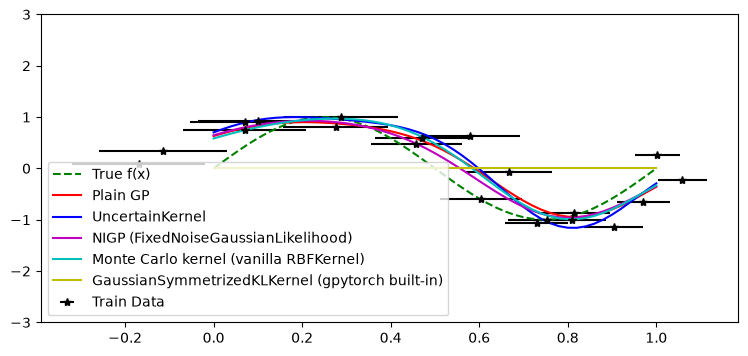

In [9]:
f, ax = plt.subplots(1, 1, figsize=(9, 4))
ax.errorbar(train_x_mean.numpy(), train_y.numpy(), xerr=train_x_stdv.numpy(), fmt='k*', label='Train Data')
ax.plot(test_x.numpy(), test_y.numpy(), 'g--', label='True f(x)')
ax.plot(test_x.numpy(), plain_pred.mean.numpy(), 'r', label='Plain GP')
ax.plot(test_x.numpy(), uncertain_pred.mean.numpy(), 'b', label='UncertainKernel')
ax.plot(test_x.numpy(), nigp_pred.mean.numpy(), 'm', label='NIGP (FixedNoiseGaussianLikelihood)')
ax.plot(test_x.numpy(), mc_pred.mean.numpy(), 'c', label='Monte Carlo kernel (vanilla RBFKernel)')
ax.plot(test_x.numpy(), gsymkl_pred.mean.numpy(), 'y', label='GaussianSymmetrizedKLKernel (gpytorch built-in)')
ax.set_ylim([-3, 3])
ax.legend()

In [10]:
def mae(pred):
    return torch.mean(torch.abs(test_y - pred.mean)).item()


print('Plain GP MAE:        %.4f' % mae(plain_pred))
print('UncertainKernel MAE: %.4f' % mae(uncertain_pred))
print('NIGP MAE:            %.4f' % mae(nigp_pred))
print('Monte Carlo MAE:     %.4f' % mae(mc_pred))
print('GaussianSymKL MAE:   %.4f' % mae(gsymkl_pred))

Plain GP MAE:        0.2535
UncertainKernel MAE: 0.3019
NIGP MAE:            0.2010
Monte Carlo MAE:     0.2437
GaussianSymKL MAE:   0.6233


## Multi-seed calibration study

Average MAE and predictive-variance calibration over 10 random seeds, using each model's
**latent-function** variance compared against squared error to the clean ground truth `test_y` -- this
isolates epistemic (input-uncertainty) calibration from observation noise:

- **MSSE** (mean standardized squared error, `err^2 / pred_var`) targets ~1 for well-calibrated variance.
- **Coverage95** (fraction of test points within `±1.96 * pred_std`) targets ~0.95.
- **NLPD** (negative log predictive density) rewards both accurate means and calibrated variance -- lower is better.

In [11]:
def calibration_metrics(pred_mean, pred_var, test_y):
    err2 = (test_y - pred_mean) ** 2
    msse = (err2 / pred_var).mean().item()  # ~1 means well-calibrated variance
    std = pred_var.sqrt()
    coverage95 = ((test_y - pred_mean).abs() <= 1.96 * std).float().mean().item()
    nlpd = (0.5 * torch.log(2 * math.pi * pred_var) + err2 / (2 * pred_var)).mean().item()
    mae_ = err2.sqrt().mean().item()
    return dict(mae=mae_, msse=msse, coverage95=coverage95, nlpd=nlpd)


n_seeds = 10
results = {'Plain GP': [], 'UncertainKernel': [], 'NIGP': [], 'Monte Carlo': [], 'GaussianSymKL': []}

for seed in range(n_seeds):
    s_train_x_mean, s_train_x_var, s_train_x_stdv, s_train_y, s_test_x, s_test_y = make_data(seed)

    s_plain_likelihood = gpytorch.likelihoods.GaussianLikelihood()
    s_plain_model = PlainGPModel(s_train_x_mean.unsqueeze(-1), s_train_y, s_plain_likelihood)
    s_plain_model, s_plain_likelihood = train_exact_gp(
        s_plain_model, s_plain_likelihood, s_train_x_mean.unsqueeze(-1), s_train_y
    )
    with torch.no_grad():
        s_plain_pred = s_plain_model(s_test_x.unsqueeze(-1))  # latent f, compared against clean test_y
    results['Plain GP'].append(calibration_metrics(s_plain_pred.mean, s_plain_pred.variance, s_test_y))

    s_inputsZipped = torch.stack((s_train_x_mean, s_train_x_var), dim=1)
    s_uncertain_likelihood = gpytorch.likelihoods.GaussianLikelihood()
    s_uncertain_model = UncertainGPModel(s_inputsZipped, s_train_y, s_uncertain_likelihood)
    s_uncertain_model, s_uncertain_likelihood = train_exact_gp(
        s_uncertain_model, s_uncertain_likelihood, s_inputsZipped, s_train_y
    )
    with torch.no_grad(), gpytorch.settings.lazily_evaluate_kernels(False):
        s_test_x_distributional = torch.stack((s_test_x, torch.zeros_like(s_test_x)), dim=1)
        s_uncertain_pred = s_uncertain_model(s_test_x_distributional)
    results['UncertainKernel'].append(
        calibration_metrics(s_uncertain_pred.mean, s_uncertain_pred.variance, s_test_y)
    )

    s_nigp_model, s_nigp_likelihood = fit_nigp(
        s_plain_model, s_plain_likelihood, s_train_x_mean, s_train_y, s_train_x_var
    )
    with torch.no_grad():
        s_nigp_pred = s_nigp_model(s_test_x.unsqueeze(-1))  # latent f
    results['NIGP'].append(calibration_metrics(s_nigp_pred.mean, s_nigp_pred.variance, s_test_y))

    s_mc_likelihood = gpytorch.likelihoods.GaussianLikelihood()
    s_mc_model = MonteCarloGPModel(s_inputsZipped, s_train_y, s_mc_likelihood, n_samples=32)
    s_mc_model, s_mc_likelihood = train_exact_gp(s_mc_model, s_mc_likelihood, s_inputsZipped, s_train_y)
    s_mc_model.covar_module.base_kernel.n_samples = 256  # reduce MC noise for evaluation
    with torch.no_grad(), gpytorch.settings.lazily_evaluate_kernels(False):
        s_mc_pred = s_mc_model(s_test_x_distributional)
    results['Monte Carlo'].append(calibration_metrics(s_mc_pred.mean, s_mc_pred.variance, s_test_y))

    s_inputsLogVar = torch.stack((s_train_x_mean, s_train_x_var.log()), dim=1)
    s_gsymkl_likelihood = gpytorch.likelihoods.GaussianLikelihood()
    s_gsymkl_model = GaussianSymKLGPModel(s_inputsLogVar, s_train_y, s_gsymkl_likelihood)
    s_gsymkl_model, s_gsymkl_likelihood = train_exact_gp(s_gsymkl_model, s_gsymkl_likelihood, s_inputsLogVar, s_train_y)
    with torch.no_grad(), gpytorch.settings.lazily_evaluate_kernels(False):
        s_test_x_logvar = torch.stack((s_test_x, torch.zeros_like(s_test_x).log()), dim=1)
        s_gsymkl_pred = s_gsymkl_model(s_test_x_logvar)
    results['GaussianSymKL'].append(calibration_metrics(s_gsymkl_pred.mean, s_gsymkl_pred.variance, s_test_y))

print('%-18s %8s %8s %10s %8s' % ('Model', 'MAE', 'MSSE', 'Coverage95', 'NLPD'))
for name, rows in results.items():
    mae_avg = sum(r['mae'] for r in rows) / n_seeds
    msse_avg = sum(r['msse'] for r in rows) / n_seeds
    cov_avg = sum(r['coverage95'] for r in rows) / n_seeds
    nlpd_avg = sum(r['nlpd'] for r in rows) / n_seeds
    print('%-18s %8.4f %8.4f %10.4f %8.4f' % (name, mae_avg, msse_avg, cov_avg, nlpd_avg))

Model                   MAE     MSSE Coverage95     NLPD
Plain GP             0.2399   2.5279     0.7647   0.4558
UncertainKernel      0.2066   1.2889     0.9059   0.0975
NIGP                 0.2313   2.3975     0.8000   0.3914
Monte Carlo          0.2017   1.6181     0.8784   0.2016
GaussianSymKL        0.6233   1.5238     0.9686   1.1241


## GPyTorch's tutorial variance schedule, genuinely jittered

The [GaussianSymmetrizedKLKernel tutorial](https://docs.gpytorch.ai/en/stable/examples/01_Exact_GPs/GP_Regression_DistributionalKernel.html)'s
data-generation code is essentially identical to `kernelTesting.ipynb`'s -- `kernelTesting.ipynb` was very
likely built by copying this tutorial and swapping in `UncertainKernel`. Both, as published, do **not**
actually jitter the training inputs: `train_x_mean` is the exact grid `train_y` is generated from;
`train_x_stdv` is attached as metadata only, never used to displace anything. That means none of them are
actually testing input-noise-awareness -- see the discussion above.

This section reruns the tutorial's own `train_x_stdv` schedule (`0.03` down to `0.01`, tighter than the
`make_data()` schedule used elsewhere in this notebook) but with genuine jitter applied, the same way as
`make_data()`: `train_y` is generated from a hidden `x_true`, and every model only ever sees the noisy
observed `train_x_mean = x_true + noise`. Test points keep the tutorial's own `1e-3` variance convention.

In [12]:
torch.manual_seed(0)
tut_x_true = torch.linspace(0, 1, 20)
tut_x_stdv = torch.linspace(0.03, 0.01, 20)
tut_x_var = tut_x_stdv ** 2

tut_x_noise = torch.randn(20) * tut_x_stdv
tut_x_mean = tut_x_true + tut_x_noise  # genuinely jittered: what every model actually observes

tut_y = torch.sin(tut_x_true * (2 * math.pi)) + torch.randn(20) * 0.2  # generated from tut_x_true, not tut_x_mean

tut_test_x = torch.linspace(0, 1, 51)
tut_test_y = torch.sin(tut_test_x * (2 * math.pi))
tut_test_var = 1e-3 * torch.ones_like(tut_test_x)  # tutorial's own test-time convention (not exactly 0)

# Plain GP
tut_plain_likelihood = gpytorch.likelihoods.GaussianLikelihood()
tut_plain_model = PlainGPModel(tut_x_mean.unsqueeze(-1), tut_y, tut_plain_likelihood)
tut_plain_model, tut_plain_likelihood = train_exact_gp(
    tut_plain_model, tut_plain_likelihood, tut_x_mean.unsqueeze(-1), tut_y
)

# UncertainKernel
tut_inputsZipped = torch.stack((tut_x_mean, tut_x_var), dim=1)
tut_uncertain_likelihood = gpytorch.likelihoods.GaussianLikelihood()
tut_uncertain_model = UncertainGPModel(tut_inputsZipped, tut_y, tut_uncertain_likelihood)
tut_uncertain_model, tut_uncertain_likelihood = train_exact_gp(
    tut_uncertain_model, tut_uncertain_likelihood, tut_inputsZipped, tut_y
)

# NIGP
tut_nigp_model, tut_nigp_likelihood = fit_nigp(
    tut_plain_model, tut_plain_likelihood, tut_x_mean, tut_y, tut_x_var
)

# Monte Carlo kernel
tut_mc_likelihood = gpytorch.likelihoods.GaussianLikelihood()
tut_mc_model = MonteCarloGPModel(tut_inputsZipped, tut_y, tut_mc_likelihood, n_samples=32)
tut_mc_model, tut_mc_likelihood = train_exact_gp(tut_mc_model, tut_mc_likelihood, tut_inputsZipped, tut_y)
tut_mc_model.covar_module.base_kernel.n_samples = 256

# GaussianSymmetrizedKLKernel (gpytorch built-in)
tut_inputsLogVar = torch.stack((tut_x_mean, tut_x_var.log()), dim=1)
tut_gsymkl_likelihood = gpytorch.likelihoods.GaussianLikelihood()
tut_gsymkl_model = GaussianSymKLGPModel(tut_inputsLogVar, tut_y, tut_gsymkl_likelihood)
tut_gsymkl_model, tut_gsymkl_likelihood = train_exact_gp(
    tut_gsymkl_model, tut_gsymkl_likelihood, tut_inputsLogVar, tut_y
)

# Predictions
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    tut_plain_pred = tut_plain_likelihood(tut_plain_model(tut_test_x.unsqueeze(-1)))

with torch.no_grad(), gpytorch.settings.fast_pred_var(), gpytorch.settings.lazily_evaluate_kernels(False):
    tut_test_x_distributional = torch.stack((tut_test_x, tut_test_var), dim=1)
    tut_uncertain_pred = tut_uncertain_likelihood(tut_uncertain_model(tut_test_x_distributional))

with torch.no_grad():
    tut_test_noise = torch.full_like(tut_test_x, tut_nigp_likelihood.second_noise.item())
    tut_nigp_pred = tut_nigp_likelihood(tut_nigp_model(tut_test_x.unsqueeze(-1)), noise=tut_test_noise)

with torch.no_grad(), gpytorch.settings.lazily_evaluate_kernels(False):
    tut_mc_pred = tut_mc_likelihood(tut_mc_model(tut_test_x_distributional))

with torch.no_grad(), gpytorch.settings.lazily_evaluate_kernels(False):
    tut_test_x_logvar = torch.stack((tut_test_x, tut_test_var.log()), dim=1)
    tut_gsymkl_pred = tut_gsymkl_likelihood(tut_gsymkl_model(tut_test_x_logvar))


def tut_mae(pred):
    return torch.mean(torch.abs(tut_test_y - pred.mean)).item()


print('%-15s %10s %10s %8s' % ('Model', 'lengthscale', 'noise', 'MAE'))
print('%-15s %10.3f %10.3f %8.4f' % (
    'Plain GP', tut_plain_model.covar_module.base_kernel.lengthscale.item(),
    tut_plain_likelihood.noise.item(), tut_mae(tut_plain_pred)))
print('%-15s %10.3f %10.3f %8.4f' % (
    'UncertainKernel', tut_uncertain_model.covar_module.base_kernel.lengthscale.item(),
    tut_uncertain_likelihood.noise.item(), tut_mae(tut_uncertain_pred)))
print('%-15s %10.3f %10.4f %8.4f' % (
    'NIGP', tut_nigp_model.covar_module.base_kernel.lengthscale.item(),
    tut_nigp_likelihood.second_noise.item(), tut_mae(tut_nigp_pred)))
print('%-15s %10.3f %10.3f %8.4f' % (
    'Monte Carlo', tut_mc_model.covar_module.base_kernel.lengthscale.item(),
    tut_mc_likelihood.noise.item(), tut_mae(tut_mc_pred)))
print('%-15s %10.3f %10.3f %8.4f' % (
    'GaussianSymKL', tut_gsymkl_model.covar_module.base_kernel.lengthscale.item(),
    tut_gsymkl_likelihood.noise.item(), tut_mae(tut_gsymkl_pred)))

Model           lengthscale      noise      MAE
Plain GP             0.268      0.019   0.0932
UncertainKernel      0.267      0.019   0.0882
NIGP                 0.263     0.0066   0.0912
Monte Carlo          0.258      0.017   0.1209
GaussianSymKL       34.943      0.003   0.1997


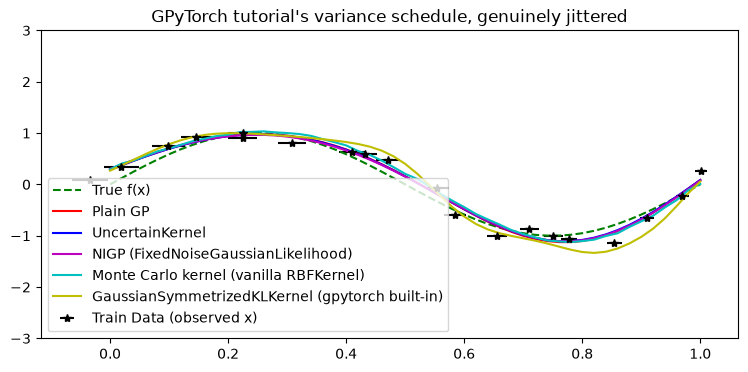

In [13]:
f, ax = plt.subplots(1, 1, figsize=(9, 4))
ax.errorbar(tut_x_mean.numpy(), tut_y.numpy(), xerr=tut_x_stdv.numpy(), fmt='k*', label='Train Data (observed x)')
ax.plot(tut_test_x.numpy(), tut_test_y.numpy(), 'g--', label='True f(x)')
ax.plot(tut_test_x.numpy(), tut_plain_pred.mean.numpy(), 'r', label='Plain GP')
ax.plot(tut_test_x.numpy(), tut_uncertain_pred.mean.numpy(), 'b', label='UncertainKernel')
ax.plot(tut_test_x.numpy(), tut_nigp_pred.mean.numpy(), 'm', label='NIGP (FixedNoiseGaussianLikelihood)')
ax.plot(tut_test_x.numpy(), tut_mc_pred.mean.numpy(), 'c', label='Monte Carlo kernel (vanilla RBFKernel)')
ax.plot(tut_test_x.numpy(), tut_gsymkl_pred.mean.numpy(), 'y', label='GaussianSymmetrizedKLKernel (gpytorch built-in)')
ax.set_ylim([-3, 3])
ax.set_title('GPyTorch tutorial\'s variance schedule, genuinely jittered')
ax.legend()